In [15]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage,HumanMessage
from langchain_groq import ChatGroq
from langgraph.checkpoint.memory import MemorySaver

In [5]:
import os
from dotenv import load_dotenv
from langchain_groq import ChatGroq

load_dotenv()

llm = ChatGroq(
    model=os.getenv("GROQ_MODEL", "openai/gpt-oss-20b"),
    api_key=os.getenv("GROQ_API_KEY"),
    temperature=0
)

In [6]:
from langgraph.graph.message import add_messages

class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [8]:
def chat_node(state:ChatState):
    messages = state['messages']

    # Send to llm
    response = llm.invoke(messages)

    # Response store state
    return {'messages': [response]}

In [16]:
checkpoint = MemorySaver()

graph = StateGraph(ChatState)

# add nodes
graph.add_node('chat_node', chat_node)

# add edges
graph.add_edge(START,'chat_node')
graph.add_edge('chat_node',END)

chatbot = graph.compile(checkpointer=checkpoint)

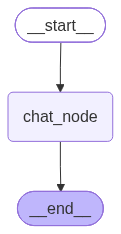

In [17]:
chatbot

In [19]:
thread_id = "1"

initial_state = {
    'messages': [HumanMessage(content="What is Object oriented programming?")]
}
config = {'configurable': {'thread_id': thread_id}}

response = chatbot.invoke(initial_state, config=config)

In [12]:
response

{'messages': [HumanMessage(content='What is Object oriented programming?', additional_kwargs={}, response_metadata={}, id='63b2710b-e3f8-41f7-a9ac-3aacbef5677c'),
  AIMessage(content='**Object‑Oriented Programming (OOP)** is a programming paradigm that organizes software design around *objects*—self‑contained units that bundle data (attributes) and behavior (methods). Instead of thinking in terms of procedures or functions that act on data, OOP encourages you to think in terms of real‑world entities and the interactions between them.\n\n---\n\n## Core Concepts\n\n| Concept | What it means | Why it matters |\n|---------|---------------|----------------|\n| **Class** | A blueprint or template that defines the structure (attributes) and capabilities (methods) of an object. | Lets you create many similar objects without rewriting code. |\n| **Object** | An instance of a class; a concrete entity with its own state. | Represents a real‑world thing in your program. |\n| **Encapsulation** | Hi

In [13]:
response['messages'][-1].content

'**Object‑Oriented Programming (OOP)** is a programming paradigm that organizes software design around *objects*—self‑contained units that bundle data (attributes) and behavior (methods). Instead of thinking in terms of procedures or functions that act on data, OOP encourages you to think in terms of real‑world entities and the interactions between them.\n\n---\n\n## Core Concepts\n\n| Concept | What it means | Why it matters |\n|---------|---------------|----------------|\n| **Class** | A blueprint or template that defines the structure (attributes) and capabilities (methods) of an object. | Lets you create many similar objects without rewriting code. |\n| **Object** | An instance of a class; a concrete entity with its own state. | Represents a real‑world thing in your program. |\n| **Encapsulation** | Hiding the internal state of an object and exposing only a well‑defined interface. | Protects data integrity and simplifies maintenance. |\n| **Inheritance** | A class can inherit attri

In [20]:
chatbot.get_state(config=config)

StateSnapshot(values={'messages': [HumanMessage(content='hi', additional_kwargs={}, response_metadata={}, id='f4f31575-e8ea-4c42-8af4-5b73e4dbb6e4'), AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "hi". We need to respond. The instruction: "You are ChatGPT, a large language model trained by OpenAI." There\'s no special instruction. Just respond politely.'}, response_metadata={'token_usage': {'completion_tokens': 57, 'prompt_tokens': 72, 'total_tokens': 129, 'completion_time': 0.059498286, 'completion_tokens_details': {'reasoning_tokens': 39}, 'prompt_time': 0.003437404, 'prompt_tokens_details': None, 'queue_time': 0.042508946, 'total_time': 0.06293569}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_80501ff3a1', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a14654-e27b-77b1-8cf3-547e120b3a87-0', tool_calls=[], invalid_tool_calls=[], usage_metad

In [18]:
thread_id = "1"

while True:
    user_message = input('Type here : ')

    print('user : ', user_message)

    if user_message.strip().lower() in ['exit', 'quit', 'bye']:
        break

    config = {'configurable': {'thread_id': thread_id}}
    response = chatbot.invoke({'messages': [HumanMessage(content=user_message)]}, config=config)
    print('AI:', response['messages'][-1].content)

user :  hi
AI: Hello! How can I help you today?
user :  My name is Ankur Kumar
AI: Nice to meet you, Ankur! How can I assist you today?
user :  what is python
AI: **Python** is a high‑level, interpreted programming language known for its readability, simplicity, and versatility. It was created by Guido van Rossum and first released in 1991. Here are some key points:

| Feature | Description |
|---------|-------------|
| **Syntax** | Clean, English‑like syntax that emphasizes readability. |
| **Interpreted** | Code runs line‑by‑line, no need for a separate compilation step. |
| **Dynamic typing** | Variables don’t need explicit type declarations. |
| **Large Standard Library** | Built‑in modules for file I/O, networking, web services, data manipulation, etc. |
| **Cross‑platform** | Runs on Windows, macOS, Linux, and many other systems. |
| **Extensible** | Can be extended with C/C++ modules for performance. |
| **Community & Ecosystem** | Huge ecosystem of third‑party packages (via PyP